<center>

# ESCUELA POLITÉCNICA NACIONAL

## FACULTAD DE INGENIERÍA DE SISTEMAS

### Materia: Recuperación de la Información

<br>

**Estudiante:** César Zapata

</center>

# 02 Procesamiento de texto, recuperación secuencial e indexación

## Objetivo

Implementar y comparar dos mecanismos de recuperación de información —búsqueda secuencial e índice invertido— sobre colecciones de libros del Proyecto Gutenberg, investigando experimentalmente su rendimiento y escalabilidad.

### Parte A. Corpus pequeño

**1. Preparación del corpus**

Utilice los 18 documentos de la colección Gutenberg disponible en NLTK.

1. Cargue los textos originales.
2. Identifique el número de documentos y sus tamaños.
3. Implemente tokenización y normalización: conversión a minúsculas, tratamiento de puntuación y caracteres especiales.

Seleccione y documente una configuración de preprocesamiento que se utilizará consistentemente en todos los experimentos.

In [1]:
%pip install nltk

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:

import nltk
from nltk.corpus import gutenberg

# Descargar el corpus
nltk.download("gutenberg")

# Obtener los identificadores de los documentos
ids = gutenberg.fileids()

# Almacenar el contenido original de cada libro
documentos = {}

for doc_id in ids:
    documentos[doc_id] = gutenberg.raw(doc_id) #uso raw previo a tokenizar

print("Número de documentos:", len(documentos))

for doc_id, texto in documentos.items():
    print(doc_id, ":", len(texto),"caracteres")


[nltk_data] Downloading package gutenberg to
[nltk_data]     C:\Users\Cesarbmm\AppData\Roaming\nltk_data...
[nltk_data]   Package gutenberg is already up-to-date!


Número de documentos: 18
austen-emma.txt : 887071 caracteres
austen-persuasion.txt : 466292 caracteres
austen-sense.txt : 673022 caracteres
bible-kjv.txt : 4332554 caracteres
blake-poems.txt : 38153 caracteres
bryant-stories.txt : 249439 caracteres
burgess-busterbrown.txt : 84663 caracteres
carroll-alice.txt : 144395 caracteres
chesterton-ball.txt : 457450 caracteres
chesterton-brown.txt : 406629 caracteres
chesterton-thursday.txt : 320525 caracteres
edgeworth-parents.txt : 935158 caracteres
melville-moby_dick.txt : 1242990 caracteres
milton-paradise.txt : 468220 caracteres
shakespeare-caesar.txt : 112310 caracteres
shakespeare-hamlet.txt : 162881 caracteres
shakespeare-macbeth.txt : 100351 caracteres
whitman-leaves.txt : 711215 caracteres


In [3]:
# Para la tokenizacion y normalizacion
import re

def procesar_texto(texto):
    tokens = re.findall(r"\b\w+\b", texto.lower())
    return tokens



**Política de preprocesamiento**

Se utiliza una misma configuración para todos los documentos y consultas:

- Conversión a minúsculas mediante `lower()`.
- Tokenización con la expresión regular `\b\w+\b`.
- Separación de palabras mediante signos de puntuación.
- Conservación de números, tildes y repeticiones.
- No se eliminan stopwords ni se aplica stemming o lematización.

Esta configuración permite mantener una representación compatible entre documentos y consultas.


In [6]:
tokens_por_documento = {}

for doc_id, texto in documentos.items():
    tokens_por_documento[doc_id] = procesar_texto(texto)

# Se usa para futuras mediciones de tiempo no incluyan la tokenización.

**2. Búsqueda secuencial**

Implemente una función que reciba un término de consulta y devuelva los identificadores de todos los documentos que lo contienen con una búsqueda secuencial.

La implementación deberá utilizar obligatoriamente dos lazos `for` anidados: el primero recorre los documentos y el segundo los tokens de cada documento.

No es necesario utilizar índices invertidos, motores de búsqueda ni estructuras auxiliares que almacenen anticipadamente los documentos asociados a cada término.

Ejecute consultas con términos frecuentes, poco frecuentes e inexistentes.

In [7]:
def busqueda_secuencial(consulta, tokens_por_documento):
    # Normalizar el término de consulta
    consulta = procesar_texto(consulta)[0]

    resultados = []

    # Recorrer documentos
    for doc_id, tokens in tokens_por_documento.items():

        # Recorrer tokens del documento
        for token in tokens:

            # Comprobar si el token coincide con la consulta
            if token == consulta:
                resultados.append(doc_id)

                # Salir del segundo for para no agregar
                # el mismo documento varias veces
                break

    return resultados

In [9]:
# Prueba con el corpues Gutenberg

print(busqueda_secuencial("the", tokens_por_documento))
print(busqueda_secuencial("emma", tokens_por_documento))
print(busqueda_secuencial("zzzxxyy987654", tokens_por_documento))

['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']
['austen-emma.txt', 'austen-persuasion.txt']
[]


**3. Medición de tiempos de ejecución**

Utilice `time.perf_counter_ns()` o una herramienta de medición equivalente para obtener el tiempo de ejecución de las consultas.

Cada medición deberá corresponder a **30 ejecuciones de la misma consulta**. Y se debe calcular la media aritmética.

Registre los resultados en milisegundos. No incluya la carga de archivos ni la tokenización dentro del tiempo de consulta.

In [11]:
import time

def medir_tiempo(funcion, consulta, datos, repeticiones=30):
    tiempos_ms = []

    for i in range(repeticiones):
        # Guardar tiempo inicial
        inicio = time.perf_counter_ns()

        # Ejecutar la función de búsqueda
        funcion(consulta, datos)

        # Guardar tiempo final
        fin = time.perf_counter_ns()

        # Calcular tiempo en milisegundos
        tiempo_ms = (fin - inicio) / 1_000_000

        # Agregar tiempo a la lista
        tiempos_ms.append(tiempo_ms)

    # Calcular promedio
    promedio = sum(tiempos_ms) / len(tiempos_ms)

    return promedio

In [12]:
consultas = ["the", "emma", "zzzxxyy987654"]

for consulta in consultas:
    promedio = medir_tiempo(
        busqueda_secuencial,
        consulta,
        tokens_por_documento
    )

    print(f"{consulta}: {promedio:.4f} ms")

the: 0.4107 ms
emma: 39.7286 ms
zzzxxyy987654: 31.8902 ms


El tiempo de búsqueda secuencial depende de la cantidad de tokens examinados y de la posición de las coincidencias. No solamente del número de documentos recuperados.

**4. Construcción del índice invertido**

Implemente un índice invertido que contenga el vocabulario de la colección y las listas de documentos asociados a cada término.

Inspeccione las listas de postings y calcule la frecuencia documental (DF) de varios términos.

Implemente consultas de un término y consultas booleanas con AND, OR y NOT.

In [13]:
def construir_indice_invertido(tokens_por_documento):
    indice = {}

    # Recorrer los documentos
    for doc_id, tokens in tokens_por_documento.items():

        # Recorrer los términos únicos de cada documento
        for termino in set(tokens):

            # Si el término no existe, crear su entrada
            if termino not in indice:
                indice[termino] = set()

            # Agregar el documento al conjunto del término
            indice[termino].add(doc_id)

    return indice

In [14]:
indice = construir_indice_invertido(tokens_por_documento)

print("Tamaño del vocabulario:", len(indice))

print("Postings de 'emma':", sorted(indice["emma"]))
print("Postings de 'the':", sorted(indice["the"]))

Tamaño del vocabulario: 42099
Postings de 'emma': ['austen-emma.txt', 'austen-persuasion.txt']
Postings de 'the': ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']


In [15]:
terminos = ["emma", "the", "whale", "zzzxxyy987654"]

for termino in terminos:
    postings = indice.get(termino, set())
    print(f"{termino}: DF = {len(postings)}")

emma: DF = 2
the: DF = 18
whale: DF = 6
zzzxxyy987654: DF = 0


In [16]:
def busqueda_indice(consulta, indice):
    termino = procesar_texto(consulta)[0]
    return sorted(indice.get(termino, set()))

In [17]:
print(busqueda_indice("emma", indice))
print(busqueda_indice("zzzxxyy987654", indice))

['austen-emma.txt', 'austen-persuasion.txt']
[]


In [18]:
def busqueda_booleana(operador, termino1, indice, termino2=None):
    # Todos los documentos del corpus
    universo = set(tokens_por_documento.keys())

    # Obtener postings del primer término
    t1 = procesar_texto(termino1)[0]
    A = indice.get(t1, set())

    if operador == "NOT":
        # Documentos que NO contienen el término
        return sorted(universo - A)

    # Obtener postings del segundo término
    t2 = procesar_texto(termino2)[0]
    B = indice.get(t2, set())

    if operador == "AND":
        # Intersección de A y B
        return sorted(A & B)

    elif operador == "OR":
        # Unión de A y B
        return sorted(A | B)

    return []

In [19]:
print(busqueda_booleana("AND", "emma", indice, "the"))
print(busqueda_booleana("OR", "emma", indice, "whale"))
print(busqueda_booleana("NOT", "emma", indice))

['austen-emma.txt', 'austen-persuasion.txt']
['austen-emma.txt', 'austen-persuasion.txt', 'bible-kjv.txt', 'bryant-stories.txt', 'chesterton-ball.txt', 'melville-moby_dick.txt', 'shakespeare-hamlet.txt', 'whitman-leaves.txt']
['austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']


**5. Comparación**

Ejecute las mismas consultas con ambos métodos.

Compruebe que recuperan exactamente los mismos identificadores de documentos y mida el tiempo medio de 30 ejecuciones para cada consulta y método.

In [20]:
tiempo_sec = medir_tiempo(
    busqueda_secuencial, "emma", tokens_por_documento
)

tiempo_ind = medir_tiempo(
    busqueda_indice, "emma", indice
)

print(f"Secuencial: {tiempo_sec:.4f} ms")
print(f"Índice: {tiempo_ind:.4f} ms")

Secuencial: 39.2600 ms
Índice: 0.0034 ms


In [21]:
import pandas as pd

consultas = ["the", "emma", "zzzxxyy987654"]

resultados_comparacion = []

for consulta in consultas:

    # Ejecutar ambos métodos
    resultado_sec = busqueda_secuencial(consulta, tokens_por_documento)
    resultado_ind = busqueda_indice(consulta, indice)

    # Comprobar si ambos resultados son iguales
    coinciden = set(resultado_sec) == set(resultado_ind)

    # Medir tiempo secuencial
    tiempo_sec = medir_tiempo(
        busqueda_secuencial,
        consulta,
        tokens_por_documento
    )

    # Medir tiempo mediante índice
    tiempo_ind = medir_tiempo(
        busqueda_indice,
        consulta,
        indice
    )

    # Calcular el factor de aceleración
    # Evitar dividir por cero
    aceleracion = tiempo_sec / tiempo_ind if tiempo_ind > 0 else float("inf")

    resultados_comparacion.append([
        consulta,
        len(resultado_sec),
        coinciden,
        tiempo_sec,
        tiempo_ind,
        aceleracion
    ])

df = pd.DataFrame(
    resultados_comparacion,
    columns=[
        "Consulta",
        "Documentos",
        "Coinciden",
        "Secuencial (ms)",
        "Índice (ms)",
        "Aceleración"
    ]
)

display(df.round(4))

,Consulta,Documentos,Coinciden,Secuencial (ms),Índice (ms),Aceleración
0,the,18,True,0.0053,0.0011,4.9505
1,emma,2,True,31.4651,0.0017,18729.2321
2,zzzxxyy987654,0,True,29.6326,0.0020,14502.0946


### Parte B. Corpus grande

**6. Descarga de Gutenberg**

Descargue el archivo oficial `txt-files.tar.zip`, de aproximadamente 11 GB, desde:

https://www.gutenberg.org/cache/epub/feeds/

Identifique los archivos TXT, evite contar distintas versiones del mismo libro como documentos independientes y registre la cantidad de documentos válidos.

In [22]:

from pathlib import Path
import zipfile

# Obtener la carpeta de trabajo del Jupyter
carpeta = Path.cwd()

# Ubicar el ZIP
ruta_zip = carpeta / "txt-files.tar.zip"

print("Carpeta actual:", carpeta)
print("¿Existe el ZIP?:", ruta_zip.exists())

if ruta_zip.exists():
    tamano_gb = ruta_zip.stat().st_size / (1024 ** 3)
    print(f"Tamaño: {tamano_gb:.2f} GiB")

    # Inspeccionar el contenido sin extraerlo
    with zipfile.ZipFile(ruta_zip, "r") as zip_ref:
        archivos = zip_ref.namelist()

        print("Entradas en ZIP:", len(archivos))
        print("\nPrimeras 10 entradas:")

        for archivo in archivos[:10]:
            print(archivo)


Carpeta actual: c:\Users\Cesarbmm\Desktop\U\R.I\RepoRI26\Deberes
¿Existe el ZIP?: True
Tamaño: 10.55 GiB
Entradas en ZIP: 1

Primeras 10 entradas:
txt-files.tar


In [23]:

import tarfile
import zipfile

with zipfile.ZipFile(ruta_zip, "r") as zip_ref:

    # Tamaño original del TAR (sin compresión ZIP)
    info = zip_ref.getinfo("txt-files.tar")
    print(f"Tamaño del TAR: {info.file_size / (1024**3):.2f} GiB")

    # Leer el TAR como flujo de datos
    with zip_ref.open("txt-files.tar") as archivo_tar:

        with tarfile.open(fileobj=archivo_tar, mode="r|") as tar:

            contador = 0

            for miembro in tar:
                if miembro.isfile():
                    print(miembro.name, "-", miembro.size, "bytes")
                    contador += 1

                if contador == 10:
                    break


Tamaño del TAR: 28.52 GiB
cache/epub/10000/pg10000.txt - 101742 bytes
cache/epub/10001/pg10001.txt - 50987 bytes
cache/epub/10002/pg10002.txt - 305330 bytes
cache/epub/10003/pg10003.txt - 379938 bytes
cache/epub/10004/pg10004.txt - 301281 bytes
cache/epub/10005/pg10005.txt - 433229 bytes
cache/epub/10006/pg10006.txt - 94352 bytes
cache/epub/10007/pg10007.txt - 181071 bytes
cache/epub/10008/pg10008.txt - 405675 bytes
cache/epub/10009/pg10009.txt - 502864 bytes


In [25]:

import re
import zipfile
import tarfile
import shutil
from pathlib import Path

# Carpeta donde guardaremos la muestra
carpeta_muestra = Path("gutenberg_muestra")
carpeta_muestra.mkdir(exist_ok=True)

ids_unicos = set()
total_txt = 0
duplicados = 0
otros_txt = 0
extraidos = 0

limite = 1000

with zipfile.ZipFile(ruta_zip, "r") as zip_ref:
    with zip_ref.open("txt-files.tar") as archivo_tar:
        with tarfile.open(fileobj=archivo_tar, mode="r|") as tar:

            for miembro in tar:
                if not miembro.isfile():
                    continue

                if not miembro.name.lower().endswith(".txt"):
                    continue

                total_txt += 1

                # Identificar ruta e ID del libro
                patron = r"cache/epub/(\d+)/pg(\d+)(?:-[^/]*)?\.txt"

                # TODO 1: aplicar re.fullmatch()
                coincidencia = re.fullmatch(patron, miembro.name)

                if coincidencia is None:
                    otros_txt += 1
                    continue

                # TODO 2: obtener el ID desde el grupo 1
                libro_id = coincidencia.group(1)

                # Validar que ambos números coincidan
                if libro_id != coincidencia.group(2):
                    otros_txt += 1
                    continue

                if libro_id in ids_unicos:
                    duplicados += 1
                    continue

                ids_unicos.add(libro_id)

                # Guardar solo los primeros 1000 libros únicos
                if extraidos < limite and miembro.size > 0:
                    archivo = tar.extractfile(miembro)

                    if archivo is not None:
                        destino = carpeta_muestra / f"{libro_id}.txt"

                        with archivo, open(destino, "wb") as salida:
                            shutil.copyfileobj(archivo, salida)

                        extraidos += 1

                if len(ids_unicos) % 5000 == 0:
                    print("Libros identificados:", len(ids_unicos))

print("Archivos TXT:", total_txt)
print("Versiones duplicadas:", duplicados)
print("TXT no conformes:", otros_txt)
print("Libros únicos candidatos:", len(ids_unicos))
print("Libros de la muestra:", extraidos)


Libros identificados: 5000
Libros identificados: 10000
Libros identificados: 15000
Libros identificados: 20000
Libros identificados: 25000
Libros identificados: 30000
Libros identificados: 35000
Libros identificados: 40000
Libros identificados: 45000
Libros identificados: 50000
Libros identificados: 55000
Libros identificados: 60000
Libros identificados: 65000
Libros identificados: 70000
Libros identificados: 75000
Archivos TXT: 78145
Versiones duplicadas: 0
TXT no conformes: 0
Libros únicos candidatos: 78145
Libros de la muestra: 1000



**Análisis del corpus Gutenberg**

Se identificaron 78.145 archivos TXT candidatos, sin encontrar identificadores duplicados ni rutas que incumplieran el patrón establecido.

Para evitar procesar los 28,52 GiB del TAR completo, se extrajeron los primeros 1.000 libros únicos según el orden del archivo. Esta selección no constituye una muestra aleatoria.

Posteriormente, los experimentos se realizaron con subconjuntos de hasta 100 documentos, debido a las restricciones de memoria del equipo.


**7. Recuperación sobre el corpus grande**

Reutilice las funciones desarrolladas en la Parte A.

1. Procese los documentos con la misma configuración de normalización.
2. Ejecute las consultas mediante búsqueda secuencial y mida los tiempos.
3. Construya el índice invertido.
4. Repita las consultas utilizando el índice.
5. Compruebe la igualdad de resultados y compare los tiempos.

Trabaje con subconjuntos de la colección de tamaños crecientes, conservando los identificadores originales. Documente los recursos de memoria y almacenamiento utilizados.

In [26]:
from pathlib import Path

archivos = sorted(
    carpeta_muestra.glob("*.txt"),
    key=lambda ruta: int(ruta.stem)
)

print("Archivos disponibles:", len(archivos))
print("Primeros cinco:", [a.name for a in archivos[:5]])

tamano_mb = sum(
    a.stat().st_size for a in archivos[:50]
) / (1024 ** 2)

print(f"Tamaño de los primeros 50: {tamano_mb:.2f} MiB")

Archivos disponibles: 1000
Primeros cinco: ['10.txt', '100.txt', '101.txt', '102.txt', '103.txt']
Tamaño de los primeros 50: 28.57 MiB


In [28]:

tokens_grande = {}
archivos_con_reemplazos = []

for ruta in archivos[:50]:

    # Leer el contenido del archivo
    texto = ruta.read_text(
        encoding="utf-8-sig",
        errors="replace"
    )

    # Comprobar posibles problemas de codificación
    if "\ufffd" in texto:
        archivos_con_reemplazos.append(ruta.name)

    if not texto.strip():
        print("Documento vacío:", ruta.name)
        continue

    # TODO 1: Obtener el ID original del libro
    doc_id = ruta.stem


    # TODO 2: Aplicar tu función procesar_texto()
    tokens_grande[doc_id] = procesar_texto(texto)

print("Documentos procesados:", len(tokens_grande))
print("Total de tokens:", sum(len(t) for t in tokens_grande.values()))
print("Archivos con posibles errores de codificación:",
      len(archivos_con_reemplazos))


Documentos procesados: 50
Total de tokens: 5295452
Archivos con posibles errores de codificación: 0


In [29]:
indice_grande = construir_indice_invertido(tokens_grande)

print("Documentos:", len(tokens_grande))
print("Vocabulario:", len(indice_grande))
print("DF de 'the':", len(indice_grande.get("the", set())))

Documentos: 50
Vocabulario: 79252
DF de 'the': 50


In [31]:

consultas = ["the", "emma", "zzzxxyy987654"]

for consulta in consultas:

    resultado_sec = busqueda_secuencial(
        consulta, tokens_grande
    )

    resultado_ind = busqueda_indice(
        consulta, indice_grande
    )

    # Comprobar igualdad como conjuntos
    coinciden = set(resultado_sec) == set(resultado_ind)

    print(
        f"{consulta}: "
        f"{len(resultado_sec)} documentos, "
        f"coinciden = {coinciden}"
    )


the: 50 documentos, coinciden = True
emma: 4 documentos, coinciden = True
zzzxxyy987654: 0 documentos, coinciden = True


In [34]:
consulta = "emma"

# Medir tiempo secuencial
tiempo_sec = medir_tiempo(
    busqueda_secuencial,
    consulta,
    tokens_grande
)

# Medir tiempo mediante índice
tiempo_ind = medir_tiempo(
    busqueda_indice,
    consulta,
    indice_grande
)

print(f"Secuencial: {tiempo_sec:.4f} ms")
print(f"Índice: {tiempo_ind:.4f} ms")

tamano_mb = sum(
    ruta.stat().st_size for ruta in archivos[:50]
) / (1024 ** 2)

print(f"Almacenamiento: {tamano_mb:.2f} MiB")

Secuencial: 75.3807 ms
Índice: 0.0025 ms
Almacenamiento: 28.57 MiB


In [ ]:

# Conservar los primeros 50 documentos
tokens_100 = tokens_grande.copy()

# Procesar únicamente los siguientes 50
for ruta in archivos[50:100]:

    texto = ruta.read_text(
        encoding="utf-8-sig",
        errors="replace"
    )

    if not texto.strip():
        continue

    # Obtener el identificador
    doc_id = ruta.stem

    # Tokenizar y guardar
    tokens_100[doc_id] = procesar_texto(texto)

print("Documentos:", len(tokens_100))
print("Tokens:", sum(len(t) for t in tokens_100.values()))


Documentos: 100
Tokens: 8513037


In [36]:
indice_100 = construir_indice_invertido(tokens_100)

In [37]:
print("Documentos:", len(tokens_100))
print("Vocabulario:", len(indice_100))

print(
    "Coinciden:",
    set(busqueda_secuencial("emma", tokens_100))
    ==
    set(busqueda_indice("emma", indice_100))
)

Documentos: 100
Vocabulario: 103438
Coinciden: True


In [38]:
import psutil
import os

proceso = psutil.Process(os.getpid())

ram_mb = proceso.memory_info().rss / (1024 ** 2)

print(f"RAM utilizada por Jupyter: {ram_mb:.2f} MiB")

RAM utilizada por Jupyter: 610.94 MiB


In [39]:

import pandas as pd

configuraciones = [
    (50, tokens_grande, indice_grande),
    (100, tokens_100, indice_100)
]

consultas = ["the", "emma", "zzzxxyy987654"]
resultados_B = []

for n, tokens, indice_actual in configuraciones:
    for consulta in consultas:

        # Obtener resultados de ambos métodos
        r_sec = busqueda_secuencial(consulta, tokens)
        r_ind = busqueda_indice(consulta, indice_actual)

        # Comparar los resultados
        coinciden = set(r_sec) == set(r_ind)

        # Medir tiempo secuencial
        tiempo_sec = medir_tiempo(
            busqueda_secuencial,
            consulta,
            tokens
        )

        # Medir tiempo mediante índice
        tiempo_ind = medir_tiempo(
            busqueda_indice,
            consulta,
            indice_actual
        )

        resultados_B.append([
            n, consulta, len(r_sec),
            coinciden, tiempo_sec, tiempo_ind
        ])

df_B = pd.DataFrame(
    resultados_B,
    columns=[
        "Documentos", "Consulta", "Encontrados",
        "Coinciden", "Secuencial (ms)", "Índice (ms)"
    ]
)

display(df_B.round(4))


,Documentos,Consulta,Encontrados,Coinciden,Secuencial (ms),Índice (ms)
0,50,the,50,True,0.0044,0.0020
1,50,emma,4,True,72.1833,0.0017
2,50,zzzxxyy987654,0,True,71.6440,0.0015
3,100,the,100,True,0.0166,0.0048
4,100,emma,9,True,123.2692,0.0018
5,100,zzzxxyy987654,0,True,115.8816,0.0015


In [40]:

# Sumar los tamaños de los primeros 100 archivos
tamano_100 = sum(
    ruta.stat().st_size for ruta in archivos[:100]
) / (1024 ** 2)

print(f"Almacenamiento de 100 documentos: {tamano_100:.2f} MiB")


Almacenamiento de 100 documentos: 46.17 MiB



**Recursos utilizados**

- 50 documentos: 28,57 MiB de almacenamiento.
- 100 documentos: 46,17 MiB de almacenamiento.
- RAM del proceso de Jupyter al evaluar los 100 documentos: 610,94 MiB.

El almacenamiento corresponde al tamaño de los archivos TXT seleccionados.

La memoria RAM corresponde al proceso completo de Python, incluyendo otras variables, tokens e índices previamente cargados. Por tanto, no representa el consumo exclusivo del índice invertido.


### Parte C. Análisis experimental de escalabilidad

**8. Tiempo de ejecución en función del corpus**

Seleccione al menos cinco tamaños crecientes del corpus grande. Como referencia, pueden utilizarse 50, 100, 250, 500 y 1.000 documentos, ampliándolos si el equipo lo permite.

Para cada tamaño $n$:

1. Ejecute una misma consulta mediante búsqueda secuencial.
2. Repítala 30 veces y calcule el tiempo promedio.
3. Construya el índice invertido correspondiente a ese subconjunto.
4. Ejecute la consulta mediante el índice, también 30 veces.
5. Registre ambos tiempos y el número total de tokens.

Elabore una **gráfica del tiempo medio de ejecución en función del número de documentos**, colocando el número de documentos en el eje X y el tiempo en milisegundos en el eje Y. Represente los dos métodos en la misma gráfica.

In [46]:
import pandas as pd
import psutil
import os
import gc

# Configuración del experimento
consulta_escalabilidad = "zzzxxyy987654"
tamanos = [10, 25, 50, 75, 100]

resultados_C = []

# Conservamos el orden de los documentos
documentos_disponibles = list(tokens_100.items())

for n in tamanos:

    # Seleccionar el subconjunto sin duplicar los tokens
    subcorpus = dict(documentos_disponibles[:n])

    # Construir índice invertido
    indice_n = construir_indice_invertido(subcorpus)

    # Verificar la equivalencia de resultados
    r_sec = busqueda_secuencial(
        consulta_escalabilidad, subcorpus
    )
    r_ind = busqueda_indice(
        consulta_escalabilidad, indice_n
    )

    coinciden = set(r_sec) == set(r_ind)

    # Medir 30 ejecuciones de cada método
    tiempo_sec = medir_tiempo(
        busqueda_secuencial,
        consulta_escalabilidad,
        subcorpus,
        repeticiones=30
    )

    tiempo_ind = medir_tiempo(
        busqueda_indice,
        consulta_escalabilidad,
        indice_n,
        repeticiones=30
    )

    total_tokens = sum(len(t) for t in subcorpus.values())

    ram_mb = (
        psutil.Process(os.getpid()).memory_info().rss
        / (1024 ** 2)
    )

    resultados_C.append({
        "Documentos": len(subcorpus),
        "Tokens": total_tokens,
        "Coinciden": coinciden,
        "Secuencial (ms)": tiempo_sec,
        "Índice (ms)": tiempo_ind,
        "RAM proceso (MiB)": ram_mb
    })

    print(f"Completado: {n} documentos")

    # Liberar el índice temporal antes del siguiente tamaño
    del indice_n, subcorpus
    gc.collect()

df_C = pd.DataFrame(resultados_C)

display(df_C.round(5))

Completado: 10 documentos
Completado: 25 documentos
Completado: 50 documentos
Completado: 75 documentos
Completado: 100 documentos


,Documentos,Tokens,Coinciden,Secuencial (ms),Índice (ms),RAM proceso (MiB)
0,10,2522751,True,34.19547,0.00188,580.79688
1,25,3545886,True,48.39819,0.00153,958.60156
2,50,5295452,True,72.48645,0.00175,969.62109
3,75,7376080,True,106.52425,0.00153,981.39844
4,100,8513037,True,116.35773,0.00154,995.28906


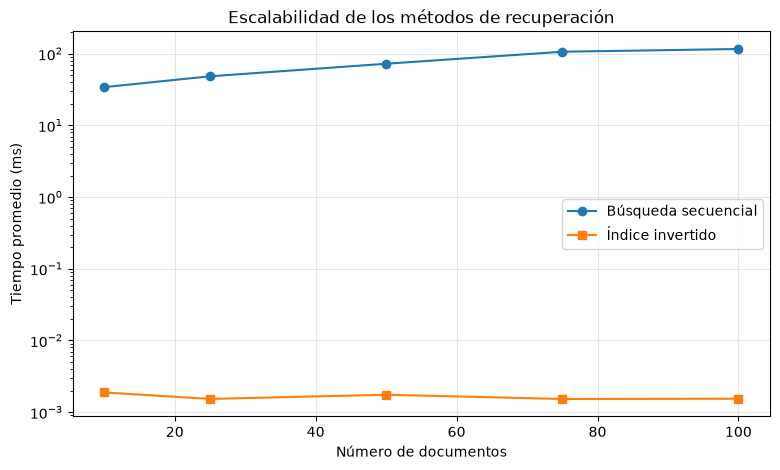

In [47]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    df_C["Documentos"],
    df_C["Secuencial (ms)"],
    marker="o",
    label="Búsqueda secuencial"
)

plt.plot(
    df_C["Documentos"],
    df_C["Índice (ms)"],
    marker="s",
    label="Índice invertido"
)

plt.xlabel("Número de documentos")
plt.ylabel("Tiempo promedio (ms)")
plt.title("Escalabilidad de los métodos de recuperación")

# Escala logarítmica para visualizar ambos métodos
plt.yscale("log")

plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**9. Estimación de una función de tiempo**

Utilizando los resultados experimentales, determine una función:

$t=f(n)$

para cada método de recuperación.

Como primera aproximación, utilice un ajuste lineal por mínimos cuadrados:

$t(n)=an+b$

Estime los parámetros $a$ y $b$, reporte el coeficiente de determinación $R^2$ y represente las funciones ajustadas junto a los datos experimentales.

Explique si el modelo lineal representa adecuadamente las mediciones y cómo se relaciona con la complejidad computacional de cada algoritmo.


Método: Secuencial (ms)
Pendiente (a): 0.96572138
Intercepto (b): 25.37490610
R²: 0.97823
t(n) = 0.96572138n + (25.37490610)


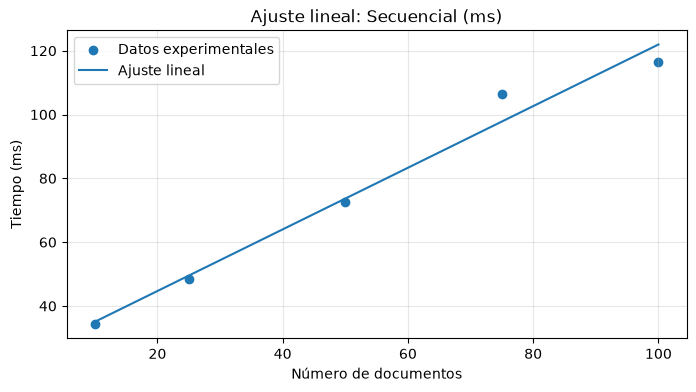


Método: Índice (ms)
Pendiente (a): -0.00000279
Intercepto (b): 0.00179114
R²: 0.39144
t(n) = -0.00000279n + (0.00179114)


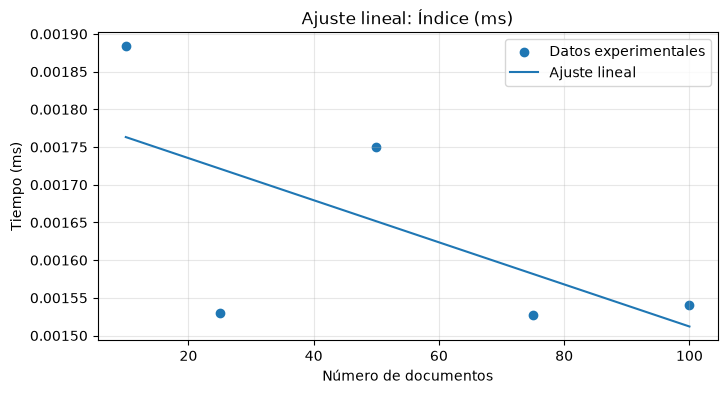

In [48]:
import numpy as np
import matplotlib.pyplot as plt

n = df_C["Documentos"].to_numpy(dtype=float)

metodos = ["Secuencial (ms)", "Índice (ms)"]

for metodo in metodos:

    tiempos = df_C[metodo].to_numpy(dtype=float)

    # Regresión lineal por mínimos cuadrados
    a, b = np.polyfit(n, tiempos, 1)

    # Tiempos estimados por el modelo
    predicciones = a * n + b

    # Coeficiente de determinación R²
    ss_res = np.sum((tiempos - predicciones) ** 2)
    ss_tot = np.sum((tiempos - np.mean(tiempos)) ** 2)

    r2 = 1 - ss_res / ss_tot if ss_tot > 0 else float("nan")

    print(f"\nMétodo: {metodo}")
    print(f"Pendiente (a): {a:.8f}")
    print(f"Intercepto (b): {b:.8f}")
    print(f"R²: {r2:.5f}")
    print(f"t(n) = {a:.8f}n + ({b:.8f})")

    # Gráfica de mediciones y ajuste
    plt.figure(figsize=(8, 4))

    plt.scatter(n, tiempos, label="Datos experimentales")
    plt.plot(n, predicciones, label="Ajuste lineal")

    plt.xlabel("Número de documentos")
    plt.ylabel("Tiempo (ms)")
    plt.title(f"Ajuste lineal: {metodo}")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()


### Limitaciones del experimento

Las mediciones consideran únicamente el tiempo de ejecución de las consultas, excluyendo la carga de archivos, tokenización y construcción del índice.

Por ello, los resultados permiten comparar la eficiencia de recuperación, pero no el coste total de preparación de cada método.

Además, las pruebas de escalabilidad se limitaron a 100 documentos debido a la memoria disponible. Los tiempos del índice invertido fueron muy pequeños, por lo que pueden presentar variaciones asociadas a la precisión de medición y a la actividad del sistema.

Los resultados de regresión lineal describen el comportamiento experimental observado, pero no demuestran por sí solos la complejidad asintótica de los algoritmos.


Búsqueda secuencial: El modelo explica aproximadamente el 97,82 % de la variación del tiempo observado. La pendiente indica un incremento estimado de 0,966 ms por documento adicional dentro del intervalo experimental.

Índice invertido: Los tiempos permanecen alrededor de 0,0015–0,0019 ms. El ajuste lineal es poco representativo. Su pendiente ligeramente negativa no significa que buscar sea más rápido a medida que aumenta el corpus; es compatible con variaciones de medición a una escala temporal muy pequeña.


### Comparación de los métodos

Se implementaron dos mecanismos de recuperación: búsqueda secuencial e índice invertido, utilizando documentos del corpus Gutenberg. En las consultas evaluadas, ambos métodos recuperaron los mismos documentos, verificando la equivalencia de sus resultados.

La búsqueda secuencial presentó tiempos dependientes de la cantidad de tokens examinados y de la posición de las coincidencias. En cambio, el índice invertido permitió localizar directamente los documentos asociados a cada término.

### Análisis de escalabilidad

Se evaluaron cinco tamaños de corpus: 10, 25, 50, 75 y 100 documentos, utilizando una consulta inexistente y 30 ejecuciones por medición.

El tiempo de búsqueda secuencial aumentó de **34,19547 ms a 116,35773 ms**, conforme el corpus creció de 2,52 a 8,51 millones de tokens. Por su parte, el índice invertido mantuvo tiempos aproximados entre **0,0015 y 0,0019 ms**, sin mostrar un crecimiento sistemático en el intervalo evaluado.

### Ajuste lineal y complejidad

Para la búsqueda secuencial se obtuvo:

**t(n) = 0,96572138n + 25,37490610**, con **R² = 0,97823**.

El ajuste representa adecuadamente las mediciones y es consistente con el recorrido completo de tokens realizado por el algoritmo. Su complejidad en el peor caso es O(T), donde T representa el número total de tokens.

Para el índice invertido se obtuvo:

**t(n) = −0,00000279n + 0,00179114**, con **R² = 0,39144**.

El bajo ajuste indica que el modelo lineal no explica adecuadamente las pequeñas variaciones observadas. Para consultas de un término, la localización de su entrada en el diccionario tiene un coste promedio O(1), sin considerar la construcción del índice ni el procesamiento de los resultados.

## 11. Conclusiones

**1. Correctitud de los algoritmos.** La búsqueda secuencial y el índice invertido recuperaron los mismos documentos para las consultas evaluadas. Esto confirmó la correcta implementación de ambos métodos bajo una política común de preprocesamiento.

**2. Eficiencia de recuperación.** El índice invertido presentó tiempos de consulta considerablemente menores, especialmente para términos inexistentes o poco frecuentes. Esto demuestra la utilidad de organizar previamente los términos de una colección.

**3. Comportamiento frente al crecimiento.** La búsqueda secuencial mostró un incremento de tiempo al aumentar el tamaño del corpus, mientras que el índice invertido mantuvo tiempos muy pequeños durante los experimentos. El ajuste lineal de la búsqueda secuencial presentó un R² de 0,97823, consistente con la tendencia observada.

**4. Limitaciones del experimento.** Por restricciones de memoria, las pruebas de escalabilidad se limitaron a 100 documentos. Además, las mediciones excluyeron la construcción del índice y el preprocesamiento, por lo que las conclusiones corresponden principalmente al rendimiento de las consultas.

En conclusión, **el índice invertido resulta más conveniente para realizar búsquedas repetidas sobre colecciones previamente indexadas**, mientras que la búsqueda secuencial constituye una alternativa sencilla que no requiere construir una estructura adicional. La elección debe considerar tanto la velocidad de consulta como los costes de preparación, actualización y almacenamiento.